# 03 · RNA-Seq extraction and molecular audit

Reading of the selected RNA file of each patient, quality checks, and construction of the molecular variables (proliferation score, luminal score, *ERBB2*).

**Inputs:** `data/processed/patient_rna_selection.csv`, RNA files  
**Outputs:** `data/processed/rna_qc.csv`, `rna_panel_tpm.csv`, `molecular_patient.csv`

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "notebooks").is_dir() and (folder / "data" / "raw" / "RNA").is_dir():
            return folder.resolve()
    raise FileNotFoundError("Project root not found (needs notebooks/ and data/raw/RNA/).")

ROOT = find_project_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

def find_folder(prefix):
    hits = [p for p in RAW.iterdir() if p.is_dir() and p.name.lower().startswith(prefix.lower())]
    if len(hits) != 1:
        raise RuntimeError(f"Expected exactly one folder starting with {prefix!r}; found {[p.name for p in hits]}")
    return hits[0]

RNA_DIR = find_folder("RNA")
CLINICAL_DIR = find_folder("clinical.project-tcga-brca")
BIOSPECIMEN_DIR = find_folder("biospecimen.project-tcga-brca")

def read_gdc(path):
    """Read a GDC TSV as text; the GDC missing marker "'--" and empty cells become NaN."""
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, low_memory=False)
    return df.replace({"'--": np.nan, "": np.nan})

print("Project root:", ROOT)

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# One colour per meaning in every figure: blue = positive / included, orange = negative, grey = neutral.
POS, NEG, GREY = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

Project root: D:\University\Research\tcga-brca-statistics


## 1. Gene panel

Values are TPM (`tpm_unstranded`, STAR - Counts, GENCODE v36), analysed as `log2(TPM + 1)`.

| Panel | Genes | Use |
|---|---|---|
| Proliferation (17) | `CCNB1 CCNE1 CDC20 CEP55 EXO1 KIF2C MELK MYBL2 NUF2 PTTG1 RRM2 TYMS UBE2C UBE2T BIRC5 ANLN MKI67` | response (mean) |
| Luminal (4) | `ESR1 PGR FOXA1 GATA3` | explanatory (mean of z-scores) |
| HER2 axis | `ERBB2` (`GRB7` as context) | explanatory |
| Context | `EGFR FOXC1 TFF1` | descriptive only |

The 17-gene score is project-defined and is not the validated 18-gene Prosigna score. `MKI67` is mRNA, not the Ki-67 protein index.

In [16]:
PROLIF = ["CCNB1", "CCNE1", "CDC20", "CEP55", "EXO1", "KIF2C", "MELK", "MYBL2", "NUF2", "PTTG1", "RRM2", "TYMS",
          "UBE2C", "UBE2T", "BIRC5", "ANLN", "MKI67"]
LUMINAL = ["ESR1", "PGR", "FOXA1", "GATA3"]
OTHER = ["ERBB2", "GRB7", "EGFR", "FOXC1", "TFF1"]
PANEL = PROLIF + LUMINAL + OTHER
assert len(set(PANEL)) == len(PANEL) == 26 and len(PROLIF) == 17

## 2. Reading the files

Each file has a comment line, 4 STAR summary rows and about 60,000 gene rows. For every file, each panel gene must appear exactly once and be protein-coding, and quality metrics are recorded. Results are cached, so the files are read only once.

In [17]:
sel = pd.read_csv(PROC / "patient_rna_selection.csv", dtype=str)
assert sel["patient_submitter_id"].is_unique
print("Selected files (one per patient):", len(sel))

def read_one(row):
    path = RNA_DIR / row["rna_relpath"]
    df = pd.read_csv(path, sep="\t", comment="#", usecols=["gene_id", "gene_name", "gene_type", "unstranded", "tpm_unstranded"])
    is_summary = df["gene_id"].str.startswith("N_")
    summ, genes = df[is_summary].set_index("gene_id")["unstranded"], df[~is_summary]
    hit = genes[genes["gene_name"].isin(PANEL)]
    counts = hit["gene_name"].value_counts()
    problems = [g for g in PANEL if counts.get(g, 0) != 1]
    if problems or (hit["gene_type"] != "protein_coding").any() or hit["tpm_unstranded"].isna().any():
        raise ValueError(f"{row['file_id']}: panel problem {problems or 'gene_type/TPM'}")
    gene_counts = int(genes["unstranded"].sum())
    qc = {"patient_submitter_id": row["patient_submitter_id"], "n_genes": len(genes),
          "genes_tpm_gt0": int((genes["tpm_unstranded"] > 0).sum()), "tpm_sum": float(genes["tpm_unstranded"].sum()),
          "gene_counts": gene_counts, "n_unmapped": int(summ.get("N_unmapped", 0)), "n_multimapping": int(summ.get("N_multimapping", 0)),
          "n_noFeature": int(summ.get("N_noFeature", 0)), "n_ambiguous": int(summ.get("N_ambiguous", 0))}
    tpm = {f"{g}_TPM": float(v) for g, v in zip(hit["gene_name"], hit["tpm_unstranded"])}
    return qc, {"patient_submitter_id": row["patient_submitter_id"], "sample_submitter_id": row["sample_submitter_id"],
                "file_id": row["file_id"], **tpm}

QC_CACHE, PANEL_CACHE = PROC / "rna_qc.csv", PROC / "rna_panel_tpm.csv"
need = {f"{g}_TPM" for g in PANEL}
ok = QC_CACHE.exists() and PANEL_CACHE.exists()
if ok:
    panel = pd.read_csv(PANEL_CACHE)
    ok = need <= set(panel.columns) and set(panel["patient_submitter_id"]) == set(sel["patient_submitter_id"])
if ok:
    qc, panel = pd.read_csv(QC_CACHE), pd.read_csv(PANEL_CACHE)
    print("Loaded cache:", panel.shape)
else:
    recs = []
    for i, row in enumerate(sel.to_dict("records"), 1):
        recs.append(read_one(row))
        if i % 250 == 0: print(f"  {i}/{len(sel)} files")
    qc = pd.DataFrame([r[0] for r in recs]); panel = pd.DataFrame([r[1] for r in recs])
    qc.to_csv(QC_CACHE, index=False); panel.to_csv(PANEL_CACHE, index=False)
    print("Read", len(recs), "files and saved the caches")
assert panel["patient_submitter_id"].is_unique and len(panel) == len(sel)

Selected files (one per patient): 1095
Loaded cache: (1095, 29)


## 3. RNA file quality

Every file should contain the same genes, TPM should sum to about 10⁶, and library sizes should be comparable between patients.

In [18]:
star_categories = ["n_unmapped", "n_multimapping", "n_noFeature", "n_ambiguous"]

qc["total_reads"] = qc["gene_counts"] + qc[star_categories].sum(axis=1)
assert (qc["total_reads"] > 0).all()

qc["pct_unmapped_or_multi"] = (
    100 * (qc["n_unmapped"] + qc["n_multimapping"]) / qc["total_reads"]
)

for name, col in {
    "unmapped": "n_unmapped",
    "multimapping": "n_multimapping",
    "noFeature": "n_noFeature",
    "ambiguous": "n_ambiguous"
}.items():
    qc[f"pct_{name}"] = 100 * qc[col] / qc["total_reads"]

# Link QC records to their selected sample and GDC file.
sel_index = sel.set_index("patient_submitter_id")
qc["sample_submitter_id"] = qc["patient_submitter_id"].map(
    sel_index["sample_submitter_id"]
)
qc["file_id"] = qc["patient_submitter_id"].map(sel_index["file_id"])

assert qc["patient_submitter_id"].is_unique
assert qc[["sample_submitter_id", "file_id"]].notna().all().all()

display(
    qc[
        ["n_genes", "genes_tpm_gt0", "tpm_sum", "gene_counts",
         "pct_unmapped_or_multi"]
    ].describe().T.round(1)
)

print(
    "Files with a different number of genes than the others:",
    int((qc["n_genes"] != qc["n_genes"].mode()[0]).sum())
)

print(
    "Files with TPM sum outside 1e6 +/- 1%:",
    int((abs(qc["tpm_sum"] / 1e6 - 1) > 0.01).sum())
)

low = qc.loc[
    qc["gene_counts"] < 0.25 * qc["gene_counts"].median(),
    "patient_submitter_id"
].tolist()

print("Files with less than 25% of the median library size:", len(low), low[:10])

# Flag unusually high unmapped/multimapping percentages using the 1.5 x IQR rule.
q1, q3 = qc["pct_unmapped_or_multi"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

qc_outliers = qc.loc[
    qc["pct_unmapped_or_multi"] > upper_fence
]

print(f"\nUpper IQR fence: {upper_fence:.2f}%")
print(f"Potential high outliers: {len(qc_outliers)}")
print("Patients above the upper fence:", len(qc_outliers))

# Inspect the 10 samples with the highest percentages.
qc_columns = [
    "patient_submitter_id", "sample_submitter_id", "file_id",
    "gene_counts", "n_unmapped", "n_multimapping",
    "pct_unmapped", "pct_multimapping",
    "pct_noFeature", "pct_ambiguous",
    "pct_unmapped_or_multi"
]

display(
    qc.sort_values("pct_unmapped_or_multi", ascending=False)
      [qc_columns]
      .head(10)
      .round(1)
)

,count,mean,std,min,25%,50%,75%,max
n_genes,1095.0,60660.0,0.0,60660.0,60660.0,60660.0,60660.0,60660.0
genes_tpm_gt0,1095.0,32497.1,2418.3,24322.0,31196.0,32567.0,33789.5,51420.0
tpm_sum,1095.0,1000000.0,0.0,1000000.0,1000000.0,1000000.0,1000000.0,1000000.0
gene_counts,1095.0,58384465.5,14409608.0,19303211.0,48050601.5,57971543.0,68506799.5,114015705.0
pct_unmapped_or_multi,1095.0,11.0,4.7,6.9,8.9,10.0,11.4,60.8


Files with a different number of genes than the others: 0
Files with TPM sum outside 1e6 +/- 1%: 0
Files with less than 25% of the median library size: 0 []

Upper IQR fence: 15.20%
Potential high outliers: 72
Patients above the upper fence: 72


,patient_submitter_id,sample_submitter_id,file_id,gene_counts,n_unmapped,n_multimapping,pct_unmapped,pct_multimapping,pct_noFeature,pct_ambiguous,pct_unmapped_or_multi
681,TCGA-C8-A12X,TCGA-C8-A12X-01A,9684fb22-becb-44dc-8d84-4c8540507c8c,28041579,44262666,7943127,51.6,9.3,2.5,4.0,60.8
569,TCGA-BH-A0DZ,TCGA-BH-A0DZ-01A,be6f8b24-e668-41c6-89f7-f4cdc8533cae,26006524,38378755,2928401,54.1,4.1,0.9,4.2,58.3
201,TCGA-A8-A08B,TCGA-A8-A08B-01A,111b2865-e7dc-45c9-b206-20b5713714bc,23466090,27666481,2673479,47.4,4.6,3.1,4.8,51.9
237,TCGA-A8-A09T,TCGA-A8-A09T-01A,e45b755d-1df6-446a-aa05-59ae1960b442,23745717,25981341,2306177,46.7,4.1,1.7,4.8,50.8
220,TCGA-A8-A094,TCGA-A8-A094-01A,0c279a15-1250-4923-bcde-96cc3fd32d42,32719627,30744881,2816393,43.1,4.0,1.9,5.1,47.1
297,TCGA-AN-A03X,TCGA-AN-A03X-01A,a2837f64-2441-4d31-befc-514f8526b1f7,36378914,34017944,3020457,43.2,3.8,1.9,4.9,47.0
179,TCGA-A8-A07B,TCGA-A8-A07B-01A,cee943a8-ea26-4b2f-b8a4-66300ccacfb5,26586182,16959150,3231048,32.8,6.3,3.8,5.7,39.1
474,TCGA-B6-A0IK,TCGA-B6-A0IK-01A,f2842246-b121-48f0-a8c5-474a8fb47036,35151175,19206393,3412489,30.5,5.4,2.2,6.2,35.9
270,TCGA-AC-A3OD,TCGA-AC-A3OD-01A,7e915086-4926-4670-9f43-e35e2d04d6c5,58602752,38061472,21668320,22.2,12.7,19.5,11.4,34.9
264,TCGA-AC-A2QH,TCGA-AC-A2QH-01A,ff570f9a-a252-496d-a452-344063851a7b,73893785,43571050,21501362,22.8,11.2,17.4,9.9,34.0


The IQR screen flagged 72 of 1,095 samples above 15.20%. The highest was TCGA-C8-A12X-01A (60.8%; 51.6% unmapped and 9.3% multimapping). The available sample metadata does not identify a single cause. These samples were retained pending further quality assessment.

## 4. Panel genes: distribution of log2(TPM + 1)

,panel,count,median,min,max,std,Q1,Q3,IQR,missing,outliers (1.5 x IQR),zero TPM (patients)
CCNB1,proliferation,1095.0,6.07,2.92,8.89,0.96,5.43,6.77,1.34,0,8,0
CCNE1,proliferation,1095.0,2.62,0.46,9.24,1.33,2.02,3.58,1.55,0,34,0
CDC20,proliferation,1095.0,5.62,1.32,9.88,1.34,4.76,6.50,1.74,0,8,0
CEP55,proliferation,1095.0,4.39,0.70,7.90,1.19,3.58,5.19,1.60,0,5,0
EXO1,proliferation,1095.0,3.40,0.40,6.37,1.17,2.54,4.19,1.65,0,0,0
KIF2C,proliferation,1095.0,4.29,0.60,7.87,1.19,3.47,5.15,1.68,0,2,0
MELK,proliferation,1095.0,4.14,0.71,7.54,1.27,3.34,5.11,1.77,0,0,0
MYBL2,proliferation,1095.0,5.57,0.25,9.95,1.61,4.41,6.71,2.30,0,2,0
NUF2,proliferation,1095.0,3.92,0.83,8.06,1.19,3.09,4.72,1.62,0,2,0
PTTG1,proliferation,1095.0,5.15,1.59,8.43,1.10,4.41,5.86,1.45,0,11,0


saved figures\03_panel_gene_distributions.png


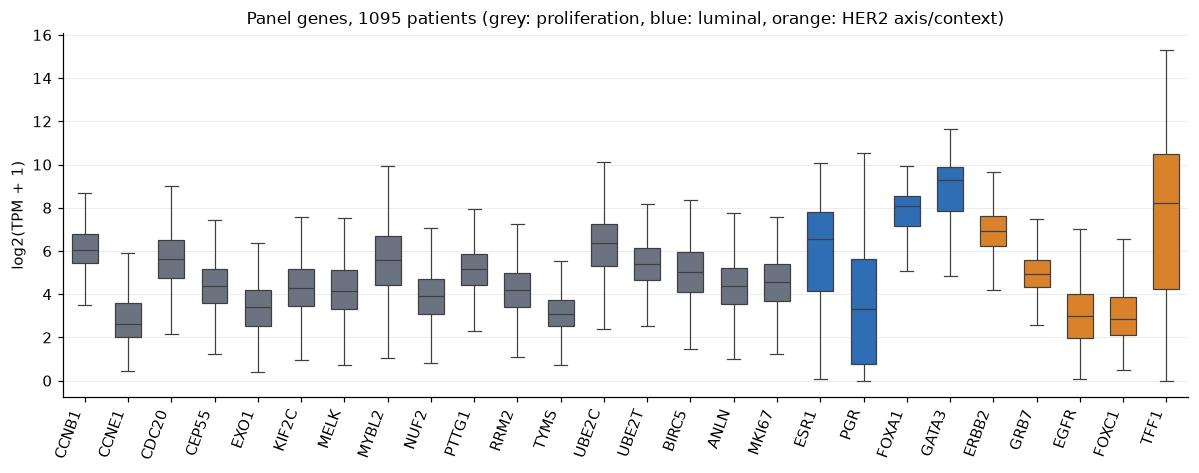

In [19]:
expr = panel.copy()
for g in PANEL:
    expr[g] = np.log2(expr[f"{g}_TPM"] + 1)

summary = expr[PANEL].agg(
    ["count", "median", "min", "max", "std"]
).T

q1 = expr[PANEL].quantile(0.25)
q3 = expr[PANEL].quantile(0.75)
iqr = q3 - q1

summary["Q1"] = q1
summary["Q3"] = q3
summary["IQR"] = iqr
summary["missing"] = expr[PANEL].isna().sum()

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

summary["outliers (1.5 x IQR)"] = (
    expr[PANEL].lt(lower) | expr[PANEL].gt(upper)
).sum()

summary["zero TPM (patients)"] = [
    (expr[f"{g}_TPM"] == 0).sum() for g in PANEL
]

summary.insert(
    0, "panel",
    ["proliferation"] * 17 + ["luminal"] * 4 + ["HER2 axis / context"] * 5
)

display(summary.round(2))

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = {"proliferation": GREY, "luminal": POS, "HER2 axis / context": NEG}
order = PANEL
bp = sns.boxplot(data=expr[order], ax=ax, showfliers=False, linewidth=0.8, width=0.6)
for patch, p in zip(ax.patches, summary["panel"]):
    patch.set_facecolor(colors[p])
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=70, ha="right")
ax.set_ylabel("log2(TPM + 1)"); ax.set_title(f"Panel genes, {len(expr)} patients (grey: proliferation, blue: luminal, orange: HER2 axis/context)")
ax.grid(axis="x", visible=False)
fig.tight_layout(); save_fig(fig, "03_panel_gene_distributions"); plt.show()

Potential outliers are flagged using the 1.5 × IQR rule. These flags are descriptive and do not imply automatic exclusion, since extreme expression values may be biologically meaningful.

## 5. Molecular variables

- **Proliferation score:** $P_i=\frac{1}{17}\sum_{g}\log_2(\mathrm{TPM}_{ig}+1)$. `MKI67` alone is kept as a secondary measure.
- **Luminal score:** $L_i=\frac14\sum_{g\in\{ESR1,PGR,FOXA1,GATA3\}} z_{ig}$, with each gene standardised over all RNA patients.
- **`ERBB2`:** `log2(TPM + 1)`.

The proliferation genes and the genes used in the other scores do not overlap. Co-expression of the 17 genes:

Pairwise Spearman among the 17 proliferation genes: median 0.78, min 0.54, max 0.93
MKI67 vs mean of the other 16 genes: Spearman 0.85
Spearman between the luminal genes: min 0.54
saved figures\03_proliferation_score.png


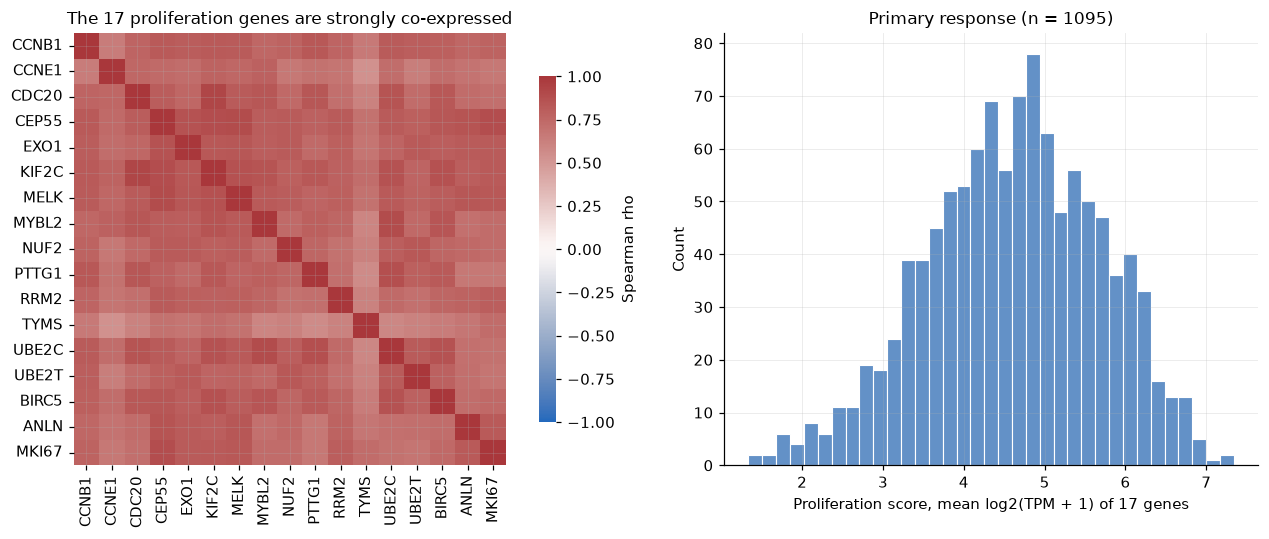

In [20]:
expr["prolif_score"] = expr[PROLIF].mean(axis=1)
z = (expr[LUMINAL] - expr[LUMINAL].mean()) / expr[LUMINAL].std(ddof=1)
expr["luminal_score"] = z.mean(axis=1)

cm = expr[PROLIF].corr(method="spearman")
offdiag = cm.values[np.triu_indices(17, 1)]
print(f"Pairwise Spearman among the 17 proliferation genes: median {np.median(offdiag):.2f}, min {offdiag.min():.2f}, max {offdiag.max():.2f}")
r_mki = expr[[g for g in PROLIF if g != "MKI67"]].mean(axis=1)
print(f"MKI67 vs mean of the other 16 genes: Spearman {expr['MKI67'].corr(r_mki, method='spearman'):.2f}")
print(f"Spearman between the luminal genes: min {expr[LUMINAL].corr(method='spearman').values[np.triu_indices(4, 1)].min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(cm, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=axes[0], cbar_kws={"label": "Spearman rho", "shrink": 0.8})
axes[0].set_title("The 17 proliferation genes are strongly co-expressed")
sns.histplot(expr["prolif_score"], bins=35, color=POS, ax=axes[1], edgecolor="white")
axes[1].set_xlabel("Proliferation score, mean log2(TPM + 1) of 17 genes"); axes[1].set_title(f"Primary response (n = {len(expr)})")
fig.tight_layout(); save_fig(fig, "03_proliferation_score"); plt.show()

In [21]:
out = expr[["patient_submitter_id", "sample_submitter_id", "file_id"] + PANEL + ["prolif_score", "luminal_score"]]
out.to_csv(PROC / "molecular_patient.csv", index=False)
print("Saved molecular_patient.csv", out.shape)

Saved molecular_patient.csv (1095, 31)


**Result.** All files pass the format checks and all panel genes are present once. The 17 proliferation genes are co-expressed, which supports averaging them into one score.